In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:

from pathlib import Path

# Define the dataset location
DATA_DIR = Path("../data/raw/london_smart_meter/Small LCL Data")

# Find all CSV files
csv_files = list(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

# Display first 10 filenames
for file in csv_files[:10]:
    print(file.name)


Number of CSV files: 168
LCL-June2015v2_0.csv
LCL-June2015v2_1.csv
LCL-June2015v2_10.csv
LCL-June2015v2_100.csv
LCL-June2015v2_101.csv
LCL-June2015v2_102.csv
LCL-June2015v2_103.csv
LCL-June2015v2_104.csv
LCL-June2015v2_105.csv
LCL-June2015v2_106.csv


In [21]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['LCLid', 'stdorToU', 'DateTime', 'KWH/hh (per half hour)']



# Smart Meter Load Profiling and Consumer Energy Consumption Clustering

## 1. Project Overview

This project focuses on analyzing electricity consumption
patterns using smart meter data.

The main objectives are:

- Analyze household electricity consumption.
- Identify daily and weekly load profiles.
- Understand peak and off-peak consumption.
- Extract meaningful consumer characteristics.
- Group consumers using machine learning clustering algorithms.

## 2. Dataset

Dataset: Low Carbon London Smart Meter Dataset

Source: UK Power Networks / London Datastore

Data format: CSV

Sampling interval: Expected half-hourly readings
(to be verified from the actual data).

## 3. Analytical Approach

Python will be used for data preprocessing,
exploratory data analysis, visualization,
feature engineering and consumer clustering.

In [5]:

# Select the first CSV file
first_file = csv_files[0]

print("Selected file:", first_file.name)

# Read only 10,000 rows
df = pd.read_csv(first_file, nrows=10000)

print("Dataset loaded successfully!")

Selected file: LCL-June2015v2_0.csv
Dataset loaded successfully!


In [6]:

df.head()

,LCLid,stdorToU,DateTime,KWH/hh (per half hour)
0,MAC000002,Std,2012-10-12 00:30:00.0000000,0
1,MAC000002,Std,2012-10-12 01:00:00.0000000,0
2,MAC000002,Std,2012-10-12 01:30:00.0000000,0
3,MAC000002,Std,2012-10-12 02:00:00.0000000,0
4,MAC000002,Std,2012-10-12 02:30:00.0000000,0


In [7]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 4


In [8]:

print("Column names:")

for column in df.columns:
    print(column)
    

Column names:
LCLid
stdorToU
DateTime
KWH/hh (per half hour) 


In [9]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   LCLid                    10000 non-null  str  
 1   stdorToU                 10000 non-null  str  
 2   DateTime                 10000 non-null  str  
 3   KWH/hh (per half hour)   10000 non-null  str  
dtypes: str(4)
memory usage: 312.6 KB


In [10]:

# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)


Missing values per column:
LCLid                      0
stdorToU                   0
DateTime                   0
KWH/hh (per half hour)     0
dtype: int64


In [11]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage:")
print(missing_percentage.round(2))


Missing value percentage:
LCLid                      0.0
stdorToU                   0.0
DateTime                   0.0
KWH/hh (per half hour)     0.0
dtype: float64


In [12]:

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)


Number of duplicate records: 7


In [13]:

df.describe(include="all").T


,count,unique,top,freq
LCLid,10000,1,MAC000002,10000
stdorToU,10000,1,Std,10000
DateTime,10000,9993,2012-10-20 00:00:00.0000000,2
KWH/hh (per half hour),10000,1065,0.074,105


In [14]:

print("Available columns:")
print(df.columns.tolist())


Available columns:
['LCLid', 'stdorToU', 'DateTime', 'KWH/hh (per half hour) ']


In [15]:

print("Unique households in sample:",
      df["LCLid"].nunique())

print("\nHousehold reading counts:")
print(df["LCLid"].value_counts().head(10))


Unique households in sample: 1

Household reading counts:
LCLid
MAC000002    10000
Name: count, dtype: int64


In [16]:

# Convert DateTime column into datetime format
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")

print("Earliest reading:", df["DateTime"].min())
print("Latest reading:", df["DateTime"].max())


Earliest reading: 2012-10-12 00:30:00
Latest reading: 2013-05-09 05:30:00


In [17]:

# Sort timestamps
timestamps = df["DateTime"].dropna().sort_values()

# Calculate time differences
time_intervals = timestamps.diff().value_counts()

print("Most common time intervals:")
print(time_intervals.head(10))


Most common time intervals:
DateTime
0 days 00:30:00    9986
0 days 00:00:00       7
0 days 01:00:00       3
1 days 00:30:00       1
0 days 00:07:27       1
0 days 00:22:33       1
Name: count, dtype: int64


In [18]:

print(df.columns.tolist())


['LCLid', 'stdorToU', 'DateTime', 'KWH/hh (per half hour) ']


In [22]:


# Identify the consumption column
consumption_column = "KWH/hh (per half hour)"

# Convert consumption into numeric values
df[consumption_column] = pd.to_numeric(
    df[consumption_column],
    errors="coerce"
)

# Display statistical summary
print(df[consumption_column].describe())



count    9999.000000
mean        0.263248
std         0.258441
min         0.000000
25%         0.114000
50%         0.179000
75%         0.287500
max         2.994000
Name: KWH/hh (per half hour), dtype: float64


In [20]:
# Display all column names
print(df.columns.tolist())

['LCLid', 'stdorToU', 'DateTime', 'KWH/hh (per half hour) ']


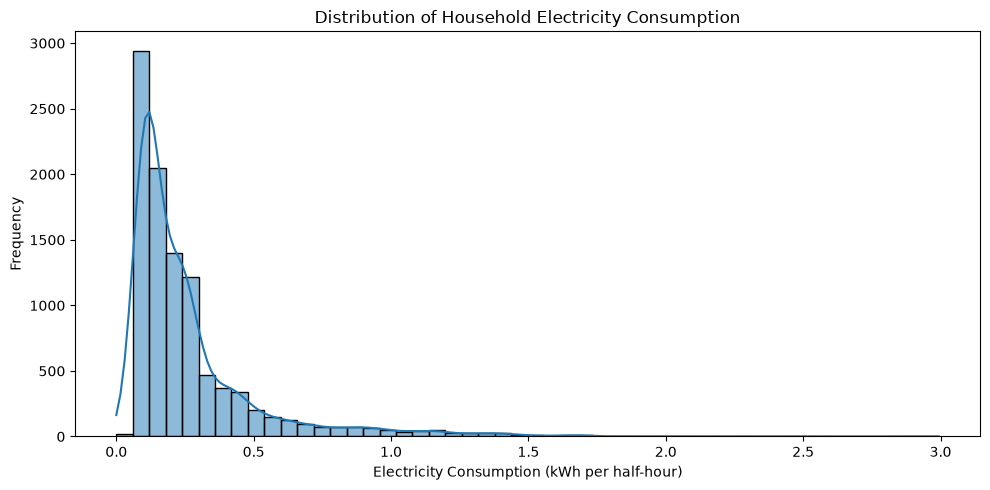

In [23]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=consumption_column,
    bins=50,
    kde=True
)

plt.title("Distribution of Household Electricity Consumption")
plt.xlabel("Electricity Consumption (kWh per half-hour)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


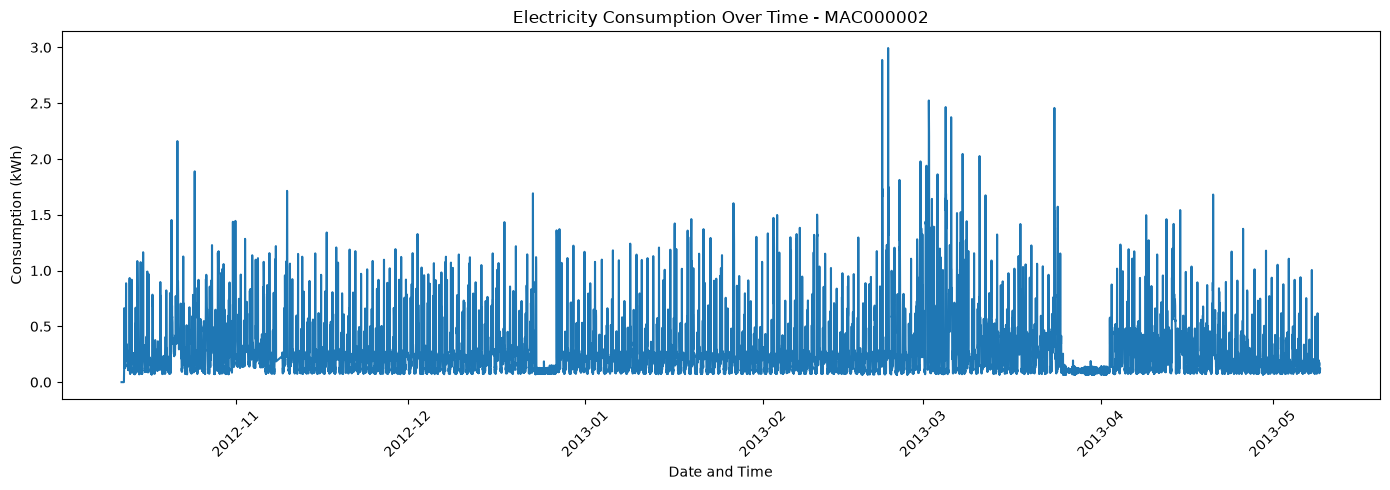

In [24]:

# Select the first household
sample_household = df["LCLid"].dropna().iloc[0]

# Filter readings for that household
household_data = df[df["LCLid"] == sample_household].copy()

# Sort by timestamp
household_data = household_data.sort_values("DateTime")

# Plot consumption
plt.figure(figsize=(14, 5))

plt.plot(
    household_data["DateTime"],
    household_data[consumption_column]
)

plt.title(f"Electricity Consumption Over Time - {sample_household}")
plt.xlabel("Date and Time")
plt.ylabel("Consumption (kWh)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


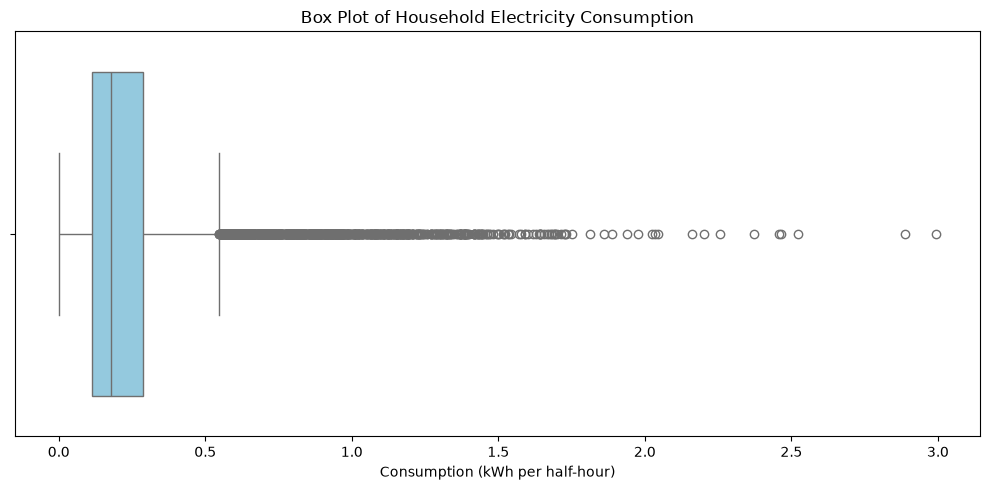

In [25]:

# Box Plot - Electricity Consumption

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df[consumption_column],
    color="skyblue"
)

plt.title("Box Plot of Household Electricity Consumption")
plt.xlabel("Consumption (kWh per half-hour)")

plt.tight_layout()
plt.show()


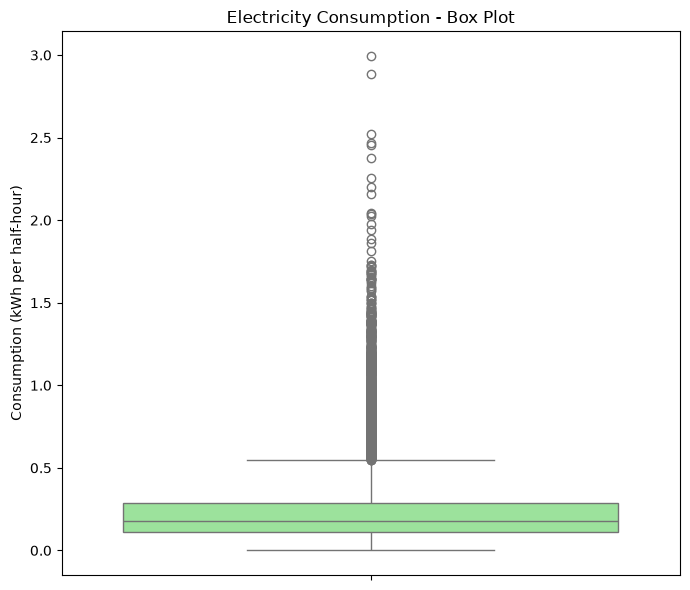

In [26]:

plt.figure(figsize=(7, 6))

sns.boxplot(
    y=df[consumption_column],
    color="lightgreen"
)

plt.title("Electricity Consumption - Box Plot")
plt.ylabel("Consumption (kWh per half-hour)")

plt.tight_layout()
plt.show()



## Initial Observations

The initial dataset exploration was performed using
a sample of 10,000 records from the first CSV file.

The following aspects were investigated:

1. Dataset dimensions and structure.
2. Household identification.
3. Missing and duplicate records.
4. Data types and timestamp information.
5. Electricity consumption statistics.
6. Initial consumption distribution.
7. Consumption behaviour over time.

Further preprocessing and analysis will be performed
after examining the complete dataset.


In [27]:

Q1 = df[consumption_column].quantile(0.25)
Q3 = df[consumption_column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[consumption_column] < lower_bound) |
    (df[consumption_column] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of potential outliers:", len(outliers))


Q1: 0.114
Q3: 0.2875
IQR: 0.1735
Lower Bound: -0.14625
Upper Bound: 0.54775
Number of potential outliers: 955
